In [1]:
import pandas as pd
import numpy as np

In [2]:
df = pd.read_csv("loan_prediction.csv")

In [3]:
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

Dataset shape: (614, 13)

Column names:
['Loan_ID', 'Gender', 'Married', 'Dependents', 'Education', 'Self_Employed', 'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term', 'Credit_History', 'Property_Area', 'Loan_Status']


In [4]:
df.head()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            614 non-null    object 
 1   Gender             601 non-null    object 
 2   Married            611 non-null    object 
 3   Dependents         599 non-null    object 
 4   Education          614 non-null    object 
 5   Self_Employed      582 non-null    object 
 6   ApplicantIncome    614 non-null    int64  
 7   CoapplicantIncome  614 non-null    float64
 8   LoanAmount         592 non-null    float64
 9   Loan_Amount_Term   600 non-null    float64
 10  Credit_History     564 non-null    float64
 11  Property_Area      614 non-null    object 
 12  Loan_Status        614 non-null    object 
dtypes: float64(4), int64(1), object(8)
memory usage: 62.5+ KB


In [7]:
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, classification_report,
    ConfusionMatrixDisplay, RocCurveDisplay
)

***EDA***

In [8]:
print(df.isnull().sum())

Loan_ID               0
Gender               13
Married               3
Dependents           15
Education             0
Self_Employed        32
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount           22
Loan_Amount_Term     14
Credit_History       50
Property_Area         0
Loan_Status           0
dtype: int64


In [9]:
print(df.isnull().sum().sum())

149


In [10]:
print(df.duplicated().sum())

0


In [12]:
print(df.dtypes)

Loan_ID               object
Gender                object
Married               object
Dependents            object
Education             object
Self_Employed         object
ApplicantIncome        int64
CoapplicantIncome    float64
LoanAmount           float64
Loan_Amount_Term     float64
Credit_History       float64
Property_Area         object
Loan_Status           object
dtype: object


In [13]:
print("Loan Approval Counts:")
print(df["Loan_Status"].value_counts())

Loan Approval Counts:
Loan_Status
Y    422
N    192
Name: count, dtype: int64


In [14]:
print("\nLoan Approval Percentages:")
print((df["Loan_Status"].value_counts(normalize=True)*100).round(2))


Loan Approval Percentages:
Loan_Status
Y    68.73
N    31.27
Name: proportion, dtype: float64


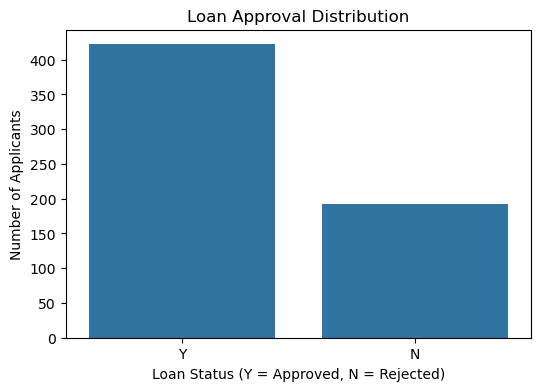

In [15]:
plt.figure(figsize=(6,4))
sns.countplot(data=df, x="Loan_Status")
plt.title("Loan Approval Distribution")
plt.xlabel("Loan Status (Y = Approved, N = Rejected)")
plt.ylabel("Number of Applicants")
plt.show()

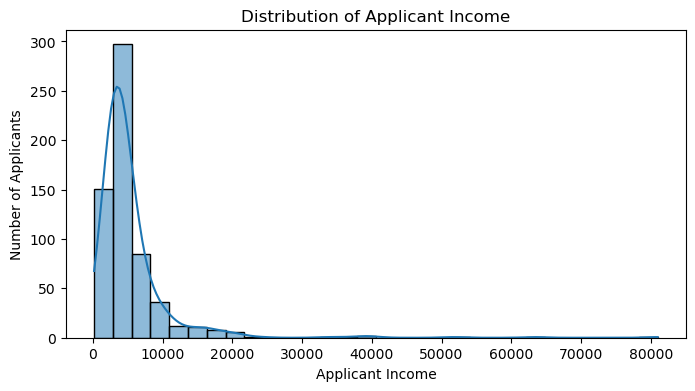

In [16]:
plt.figure(figsize=(8,4))
sns.histplot(data=df, x="ApplicantIncome", bins=30, kde=True)
plt.title("Distribution of Applicant Income")
plt.xlabel("Applicant Income")
plt.ylabel("Number of Applicants")
plt.show()

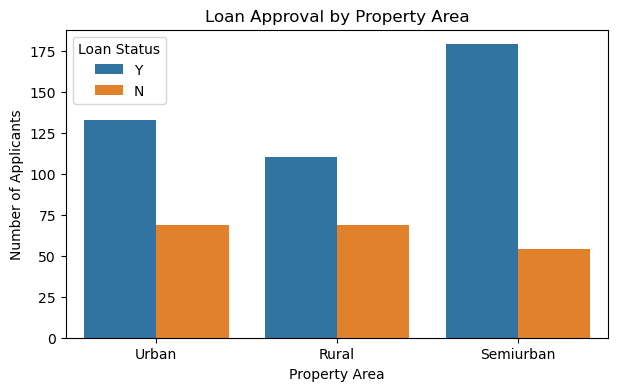

In [17]:
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x="Property_Area", hue="Loan_Status")
plt.title("Loan Approval by Property Area")
plt.xlabel("Property Area")
plt.ylabel("Number of Applicants")
plt.legend(title="Loan Status")
plt.show()

In [18]:
# Work on a copy so the original dataset remains unchanged
df_clean = df.copy()

# Remove the applicant/loan identifier
df_clean.drop(columns=["Loan_ID"], inplace=True, errors="ignore")

# Convert 3+ dependents into 3
df_clean["Dependents"] = df_clean["Dependents"].replace("3+", "3")

# Convert Dependents to numeric
df_clean["Dependents"] = pd.to_numeric(
    df_clean["Dependents"], errors="coerce"
)

# Encode the target: Y = 1, N = 0
df_clean["Loan_Status"] = (
    df_clean["Loan_Status"]
    .astype(str)
    .str.strip()
    .str.upper()
    .map({"Y": 1, "N": 0})
)

# Remove rows without a valid target label
df_clean.dropna(subset=["Loan_Status"], inplace=True)

df_clean["Loan_Status"] = df_clean["Loan_Status"].astype(int)

print("Cleaned dataset shape:", df_clean.shape)
display(df_clean.head())

Cleaned dataset shape: (614, 12)


,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,Male,No,0.0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,1
1,Male,Yes,1.0,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,0
2,Male,Yes,0.0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,1
3,Male,Yes,0.0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,1
4,Male,No,0.0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,1


***Model Trainig***

In [20]:
x = df_clean.drop(columns=["Loan_Status"])
y = df_clean["Loan_Status"]

In [30]:
print("Features shape:", x.shape)
print("Target shape:", y.shape)

Features shape: (614, 11)
Target shape: (614,)


In [31]:
print("\Target distribution:")
print(y.value_counts())

\Target distribution:
Loan_Status
1    422
0    192
Name: count, dtype: int64


In [32]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", x_train.shape)
print("Testing features:", x_test.shape)

print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (491, 11)
Testing features: (123, 11)
Training target: (491,)
Testing target: (123,)


In [33]:
numeric_features = x_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = x_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Numerical features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)

Numerical features:
['Dependents', 'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term', 'Credit_History']

Categorical features:
['Gender', 'Married', 'Education', 'Self_Employed', 'Property_Area']


In [34]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

# Process numerical features
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Process categorical features
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both pipelines
preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [36]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        max_depth=8,
        min_samples_leaf=3,
        class_weight="balanced",
        random_state=42
    )
}

trained_models = {}

for name, classifier in models.items():

    model_pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", classifier)
    ])

    # Train the complete pipeline
    model_pipeline.fit(x_train, y_train)

    trained_models[name] = model_pipeline

    print(f"{name} trained successfully!")

print("\nBoth models are ready.")

Logistic Regression trained successfully!
Random Forest trained successfully!

Both models are ready.


In [37]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

results = []

for name, model in trained_models.items():

    y_pred = model.predict(x_test)
    y_prob = model.predict_proba(x_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "F1-Score": f1_score(
            y_test, y_pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

results_df = pd.DataFrame(results)

display(
    results_df.style.format({
        "Accuracy": "{:.3f}",
        "Precision": "{:.3f}",
        "Recall": "{:.3f}",
        "F1-Score": "{:.3f}",
        "ROC-AUC": "{:.3f}"
    })
)

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.821,0.862,0.882,0.872,0.853
1,Random Forest,0.805,0.835,0.894,0.864,0.799


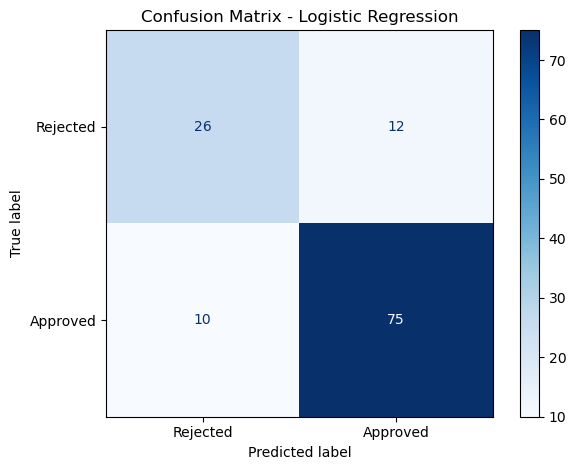

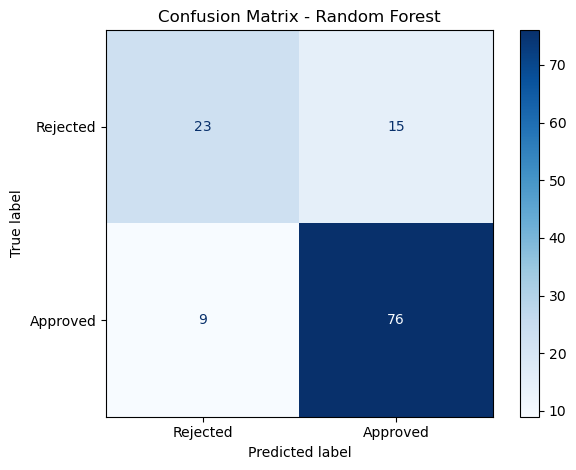

In [38]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

for name, model in trained_models.items():

    y_pred = model.predict(x_test)

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_pred,
        display_labels=["Rejected", "Approved"],
        cmap="Blues"
    )

    plt.title(f"Confusion Matrix - {name}")
    plt.tight_layout()
    plt.show()

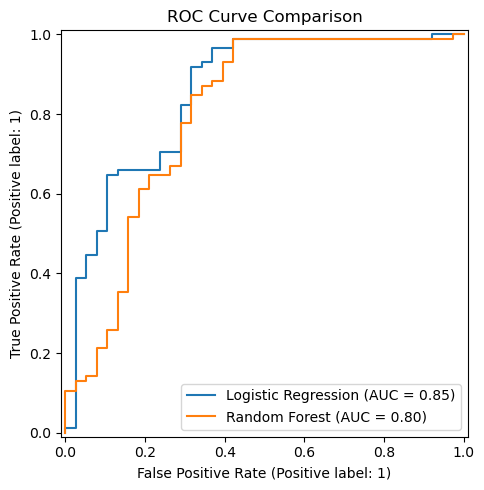

In [40]:
from sklearn.metrics import RocCurveDisplay

fig, ax = plt.subplots(figsize=(8, 5))

for name, model in trained_models.items():
    RocCurveDisplay.from_estimator(
        model,
        x_test,
        y_test,
        name=name,
        ax=ax
    )

ax.set_title("ROC Curve Comparison")
plt.tight_layout()
plt.show()

In [41]:
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from sklearn.ensemble import ExtraTreesClassifier, RandomForestClassifier
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
import pandas as pd
import numpy as np

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("Model tuning is ready!")

Model tuning is ready!


In [43]:
search_spaces = {
    "Random Forest": (
        RandomForestClassifier(
            random_state=42,
            class_weight="balanced"
        ),
        {
            "classifier__n_estimators": [100, 200, 300, 500],
            "classifier__max_depth": [None, 5, 8, 10, 15, 20],
            "classifier__min_samples_split": [2, 5, 10, 15],
            "classifier__min_samples_leaf": [1, 2, 3, 5],
            "classifier__max_features": ["sqrt", "log2", None]
        }
    ),

    "Extra Trees": (
        ExtraTreesClassifier(
            random_state=42,
            class_weight="balanced"
        ),
        {
            "classifier__n_estimators": [100, 200, 300, 500],
            "classifier__max_depth": [None, 5, 8, 10, 15, 20],
            "classifier__min_samples_split": [2, 5, 10, 15],
            "classifier__min_samples_leaf": [1, 2, 3, 5],
            "classifier__max_features": ["sqrt", "log2", None]
        }
    ),

    "SVM": (
        SVC(
            probability=True,
            class_weight="balanced",
            random_state=42
        ),
        [
            {
                "classifier__kernel": ["rbf"],
                "classifier__C": [0.1, 1, 10, 100],
                "classifier__gamma": ["scale", "auto", 0.01, 0.1]
            },
            {
                "classifier__kernel": ["linear"],
                "classifier__C": [0.1, 1, 10, 100]
            }
        ]
    )
}

search_results = []
best_estimators = {}

for name, (classifier, parameters) in search_spaces.items():

    print(f"\nTuning {name}...")

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", classifier)
    ])

    search = RandomizedSearchCV(
        estimator=pipeline,
        param_distributions=parameters,
        n_iter=15,
        scoring="accuracy",
        cv=cv,
        random_state=42,
        n_jobs=-1,
        refit=True,
        error_score="raise"
    )

    search.fit(x_train, y_train)

    best_estimators[name] = search.best_estimator_

    search_results.append({
        "Model": name,
        "Best CV Accuracy": search.best_score_,
        "Best Parameters": search.best_params_
    })

    print("Best CV accuracy:", round(search.best_score_, 4))
    print("Best parameters:", search.best_params_)

print("\nTuning completed!")


Tuning Random Forest...
Best CV accuracy: 0.7759
Best parameters: {'classifier__n_estimators': 200, 'classifier__min_samples_split': 2, 'classifier__min_samples_leaf': 2, 'classifier__max_features': 'log2', 'classifier__max_depth': 10}

Tuning Extra Trees...
Best CV accuracy: 0.7677
Best parameters: {'classifier__n_estimators': 100, 'classifier__min_samples_split': 10, 'classifier__min_samples_leaf': 1, 'classifier__max_features': None, 'classifier__max_depth': 5}

Tuning SVM...
Best CV accuracy: 0.7983
Best parameters: {'classifier__kernel': 'linear', 'classifier__C': 1}

Tuning completed!


In [45]:
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score

all_candidates = {
    "Logistic Regression": trained_models["Logistic Regression"],
    **best_estimators
}

comparison = []

for name, model in all_candidates.items():

    accuracy_scores = cross_val_score(
        model, x_train, y_train,
        cv=cv, scoring="accuracy", n_jobs=-1
    )

    f1_scores = cross_val_score(
        model, x_train, y_train,
        cv=cv, scoring="f1", n_jobs=-1
    )

    comparison.append({
        "Model": name,
        "Mean CV Accuracy": accuracy_scores.mean(),
        "CV Accuracy Std": accuracy_scores.std(),
        "Mean CV F1": f1_scores.mean()
    })

comparison_df = pd.DataFrame(comparison).sort_values(
    "Mean CV Accuracy", ascending=False
).reset_index(drop=True)

display(
    comparison_df.style.format({
        "Mean CV Accuracy": "{:.3f}",
        "CV Accuracy Std": "{:.3f}",
        "Mean CV F1": "{:.3f}"
    })
)

,Model,Mean CV Accuracy,CV Accuracy Std,Mean CV F1
0,SVM,0.798,0.046,0.870
1,Random Forest,0.776,0.067,0.850
2,Extra Trees,0.768,0.044,0.843
3,Logistic Regression,0.733,0.075,0.811


In [46]:
best_name = comparison_df.iloc[0]["Model"]
best_model = all_candidates[best_name]

print("Selected model:", best_name)

y_pred = best_model.predict(x_test)
y_prob = best_model.predict_proba(x_test)[:, 1]

from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score, roc_auc_score,
    classification_report
)

print("\nFinal held-out test results")
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(
    precision_score(y_test, y_pred, zero_division=0), 4
))
print("Recall:", round(
    recall_score(y_test, y_pred, zero_division=0), 4
))
print("F1-score:", round(
    f1_score(y_test, y_pred, zero_division=0), 4
))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 4))

print("\nClassification report:")
print(classification_report(
    y_test, y_pred,
    target_names=["Rejected", "Approved"],
    zero_division=0
))

Selected model: SVM

Final held-out test results
Accuracy: 0.8537
Precision: 0.8317
Recall: 0.9882
F1-score: 0.9032
ROC-AUC: 0.7873

Classification report:
              precision    recall  f1-score   support

    Rejected       0.95      0.55      0.70        38
    Approved       0.83      0.99      0.90        85

    accuracy                           0.85       123
   macro avg       0.89      0.77      0.80       123
weighted avg       0.87      0.85      0.84       123



In [47]:
import joblib
from feature_engineering import build_pipeline, train_model

# Train final production Random Forest with Banking Feature Engineering
final_pipeline = train_model("loan_prediction.csv")

# Save the complete pipeline
joblib.dump(final_pipeline, "loan_approval_model.pkl")

print("Selected model: Random Forest with Banking Feature Engineering")
print("Model saved successfully to loan_approval_model.pkl!")

In [49]:
# Load the saved model
loaded_model = joblib.load("loan_approval_model.pkl")

# Select one applicant from the test set
sample_applicant = x_test.iloc[[0]]

# Make a prediction
prediction = loaded_model.predict(sample_applicant)[0]
probability = loaded_model.predict_proba(sample_applicant)[0, 1]

print("Applicant details:")
display(sample_applicant)

print(
    "Predicted loan status:",
    "Approved" if prediction == 1 else "Rejected"
)

print(f"Estimated approval score: {probability:.2%}")

Applicant details:


,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area
150,Male,No,0.0,Graduate,No,6277,0.0,118.0,360.0,0.0,Rural


Predicted loan status: Rejected
Estimated approval score: 28.20%


In [50]:
comparison_df.to_csv("model_comparison.csv", index=False)

print("Model comparison saved successfully!")

Model comparison saved successfully!
